<a href="https://colab.research.google.com/github/leeale2023/BA305_A9-/blob/main/chocolate_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor

# Splitting the data, cross-validation, and the model itself
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import mean_squared_error as MSE


In [8]:
PATH = "/content/chocolate.csv"
choc = pd.read_csv(PATH)
choc.head(50)

,ref,company_manufacturer,company_location,review_date,country_of_bean_origin,specific_bean_origin_or_bar_name,cocoa_percent,ingredients,most_memorable_characteristics,rating
0,2454,5150,U.S.A.,2019,Tanzania,"Kokoa Kamili, batch 1",76%,"3- B,S,C","rich cocoa, fatty, bready",3.25
1,2458,5150,U.S.A.,2019,Dominican Republic,"Zorzal, batch 1",76%,"3- B,S,C","cocoa, vegetal, savory",3.50
2,2454,5150,U.S.A.,2019,Madagascar,"Bejofo Estate, batch 1",76%,"3- B,S,C","cocoa, blackberry, full body",3.75
3,2542,5150,U.S.A.,2021,Fiji,"Matasawalevu, batch 1",68%,"3- B,S,C","chewy, off, rubbery",3.00
4,2546,5150,U.S.A.,2021,Venezuela,"Sur del Lago, batch 1",72%,"3- B,S,C","fatty, earthy, moss, nutty,chalky",3.00
5,2546,5150,U.S.A.,2021,Uganda,"Semuliki Forest, batch 1",80%,"3- B,S,C","mildly bitter, basic cocoa, fatty",3.25
6,2542,5150,U.S.A.,2021,India,"Anamalai, batch 1",68%,"3- B,S,C","milk brownie, macadamia,chewy",3.50
7,797,A. Morin,France,2012,Bolivia,Bolivia,70%,"4- B,S,C,L","vegetal, nutty",3.50
8,797,A. Morin,France,2012,Peru,Peru,63%,"4- B,S,C,L","fruity, melon, roasty",3.75
9,1011,A. Morin,France,2013,Panama,Panama,70%,"4- B,S,C,L","brief fruit note, earthy, nutty",2.75


In [9]:
# Data Cleaning
missing_summary = pd.DataFrame({
    "Missing Count": choc.isnull().sum(),
    "Missing Percentage": choc.isnull().mean() * 100
})
display(missing_summary.round(2))

,Missing Count,Missing Percentage
ref,0,0.00
company_manufacturer,0,0.00
company_location,0,0.00
review_date,0,0.00
country_of_bean_origin,0,0.00
specific_bean_origin_or_bar_name,0,0.00
cocoa_percent,0,0.00
ingredients,87,3.44
most_memorable_characteristics,0,0.00
rating,0,0.00


<Axes: xlabel='company_location', ylabel='Avg Ratings'>

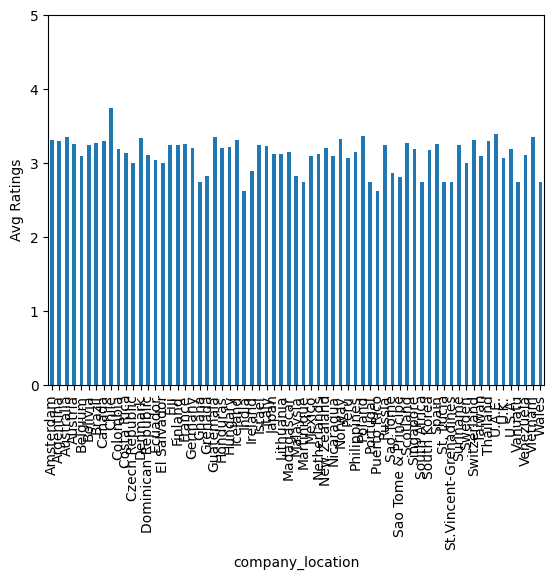

In [ ]:
comp = choc.groupby("company_location")["rating"].mean()
ax = comp.plot(kind='bar')
ax.set_ylabel('Avg Ratings')
ax.set_ylim(0, 5)
ax

In [ ]:
pd.get_dummies(choc["company_location"])
print(choc["company_location"].unique())
#Possible predictive question: Which factor of chocolate production determines the highest perception of chocolate quality?
#The origin of the bean?  Or the location of manufacturing/which manufacturer.  Which country or region leads to highest perception?

['U.S.A.' 'France' 'Fiji' 'Vanuatu' 'Ecuador' 'Mexico' 'U.K.'
 'Netherlands' 'Spain' 'Russia' 'Peru' 'Canada' 'Italy' 'Brazil'
 'Nicaragua' 'Australia' 'Philippines' 'Wales' 'Belgium' 'Vietnam'
 'Germany' 'Singapore' 'Switzerland' 'Venezuela' 'Malaysia' 'South Korea'
 'Taiwan' 'Puerto Rico' 'Colombia' 'Japan' 'New Zealand' 'Costa Rica'
 'Hungary' 'Amsterdam' 'Scotland' 'Martinique' 'Sao Tome' 'St. Lucia'
 'Argentina' 'Guatemala' 'South Africa' 'Dominican Republic'
 'Sao Tome & Principe' 'Bolivia' 'Portugal' 'Norway' 'Denmark' 'Grenada'
 'Israel' 'India' 'St.Vincent-Grenadines' 'Czech Republic' 'Thailand'
 'Finland' 'Madagascar' 'Sweden' 'Poland' 'Austria' 'Honduras' 'U.A.E.'
 'Lithuania' 'Ireland' 'Chile' 'Ghana' 'Iceland' 'Suriname' 'El Salvador']


In [ ]:
pd.get_dummies(choc["country_of_bean_origin"])
print(choc["country_of_bean_origin"].unique())


['Tanzania' 'Dominican Republic' 'Madagascar' 'Fiji' 'Venezuela' 'Uganda'
 'India' 'Bolivia' 'Peru' 'Panama' 'Colombia' 'Burma' 'Brazil'
 'Papua New Guinea' 'Ecuador' 'Cuba' 'Togo' 'Sao Tome' 'Mexico' 'Vanuatu'
 'Indonesia' 'Trinidad' 'Vietnam' 'Nicaragua' 'Ghana' 'Belize' 'Blend'
 'Jamaica' 'Grenada' 'Guatemala' 'Honduras' 'Costa Rica' 'Haiti' 'Congo'
 'Philippines' 'Solomon Islands' 'Malaysia' 'Sri Lanka' 'Ivory Coast'
 'Gabon' 'Taiwan' 'Puerto Rico' 'Martinique' 'St. Lucia' 'Australia'
 'Liberia' 'Sierra Leone' 'U.S.A.' 'Nigeria' 'St.Vincent-Grenadines'
 'Thailand' 'Tobago' 'Sao Tome & Principe' 'Sumatra' 'El Salvador'
 'Cameroon' 'Samoa' 'China' 'Principe' 'Sulawesi' 'Suriname' 'DR Congo']


In [ ]:
# Concatenate the dummy variables side-by-side to create a single features DataFrame
X = pd.concat([pd.get_dummies(choc["country_of_bean_origin"]), pd.get_dummies(choc["company_location"]),pd.get_dummies(choc["ingredients"])], axis=1)
y = choc['rating'].values

# Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

In [ ]:
# Initialize the Linear Regression model
model = LinearRegression()

# Fit the model on the training data
model.fit(X_train, y_train)

# Evaluate the model on the training data
train_r2 = model.score(X_train, y_train)
test_r2 = model.score(X_test, y_test)
print(f"Model successfully trained!")
print(f"Training R^2 Score: {train_r2:.4f}")
print(f"Model successfully tested!")
print(f"Test R^2 Score: {test_r2:.4f}")

Model successfully trained!
Training R^2 Score: 0.1749
Model successfully tested!
Test R^2 Score: -0.0356


In [ ]:
#K Fold
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=0)
kfolds = [1,5,10,50,100]
for i in kfolds:
  kfold = KFold(n_splits=i, shuffle=True, random_state=0)
model2 = KNeighborsRegressor(n_neighbors=3)
model2.fit(X,y)
y_train_fit = model.predict(X_train)                  # 4a. predict on training data
mse_train = np.mean( (y_train - y_train_fit)**2 )   # Evaluate
print(np.sqrt(mse_train), mse_train)\

AttributeError: 'KNeighborsRegressor' object has no attribute 'MSE'

In [ ]:
# Assuming the column is named 'most_memorable_characteristics'
# We clean any extra whitespace and then split by comma using .str.get_dummies()
characteristics_dummies = choc['most_memorable_characteristics'].str.strip().str.get_dummies(sep=', ')

# Display the shape of the new dummy dataframe and some of the column names (characteristics)
print(f"Created {characteristics_dummies.shape[1]} unique characteristic dummy columns.")
print("\nFirst 10 characteristic columns:")
print(list(characteristics_dummies.columns[:10]))

# Show a preview of the new dummies DataFrame
display(characteristics_dummies.head())

Created 1034 unique characteristic dummy columns.

First 10 characteristic columns:
['"Andes" mint', 'Cadbury egg', 'Easter candy', 'Fruity', 'Rich cocoa', 'Roasty', 'XL nibs', 'accesible', 'accessible', 'acidic']


,"""Andes"" mint",Cadbury egg,Easter candy,Fruity,Rich cocoa,Roasty,XL nibs,accesible,accessible,acidic,alcohol,alluring aroma,almond,almond butter,almost burnt,alocohol,aluminum,ambiguous,anise,appealing smoke,apple,artificial,ashey,assertive,astingent,astringent,atypical,baked,baked bread,balanced,banana,banana cream,banana nut,banana raspberry,"banana,dairy",base cocoa,base cocoa w/ palm notes,basic,basic chocolate,basic cocoa,...,very astringent,very bitter,very bland,very coarse,very grassy,very nutty,very roasty,very sandy,very smokey,very sour,very spicey,very spicy,very sticky,very sweet,vinegar,walnut,walnuts,watered down coffee,watering,watery,waxy,waxy mouthfeel,well balanced,well defined,well developed,wet,wheat,whole bean,wild berries,wild berry,wine,winey,wood,woodsy,woody,"woody,astringent","woody,green",wtf,yellow fruit,yogurt
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [ ]:
# 1. Clean characteristics_dummies by grouping its duplicate columns and summing them
if characteristics_dummies.columns.duplicated().any():
    print("Duplicate characteristic columns found. Aggregating them...")
    characteristics_cleaned = characteristics_dummies.T.groupby(level=0).sum().T
else:
    print("No duplicate characteristic columns found. They are already unique.")
    characteristics_cleaned = characteristics_dummies.copy()

# 2. Assign combined_features to be just the characteristics by itself
combined_features = characteristics_cleaned.astype(int)

print(f"Characteristics feature matrix shape: {combined_features.shape}")
display(combined_features.head())

No duplicate characteristic columns found. They are already unique.
Characteristics feature matrix shape: (2530, 1034)


,"""Andes"" mint",Cadbury egg,Easter candy,Fruity,Rich cocoa,Roasty,XL nibs,accesible,accessible,acidic,alcohol,alluring aroma,almond,almond butter,almost burnt,alocohol,aluminum,ambiguous,anise,appealing smoke,apple,artificial,ashey,assertive,astingent,astringent,atypical,baked,baked bread,balanced,banana,banana cream,banana nut,banana raspberry,"banana,dairy",base cocoa,base cocoa w/ palm notes,basic,basic chocolate,basic cocoa,...,very astringent,very bitter,very bland,very coarse,very grassy,very nutty,very roasty,very sandy,very smokey,very sour,very spicey,very spicy,very sticky,very sweet,vinegar,walnut,walnuts,watered down coffee,watering,watery,waxy,waxy mouthfeel,well balanced,well defined,well developed,wet,wheat,whole bean,wild berries,wild berry,wine,winey,wood,woodsy,woody,"woody,astringent","woody,green",wtf,yellow fruit,yogurt
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [ ]:
# Split the combined features dataset into training and testing sets
X_train_comb, X_test_comb, y_train_comb, y_test_comb = train_test_split(
    combined_features, y, test_size=0.3, random_state=0
)

# Initialize and train a new Linear Regression model
model_comb = LinearRegression()
model_comb.fit(X_train_comb, y_train_comb)

# Evaluate the model scores
train_r2_comb = model_comb.score(X_train_comb, y_train_comb)
test_r2_comb = model_comb.score(X_test_comb, y_test_comb)

print("--- Model Evaluation with Cleaned Characteristic Features ---")
print(f"Training R^2 Score: {train_r2_comb:.4f}")
print(f"Test R^2 Score: {test_r2_comb:.4f}")

--- Model Evaluation with Cleaned Characteristic Features ---
Training R^2 Score: 0.7732
Test R^2 Score: 0.3233


In [ ]:
# Calculate the occurrence count of each binary feature
feature_counts = combined_features.sum().sort_values(ascending=False)

# Display the sorted frequency counts
print("Feature counts sorted in descending order (displaying the top 100 without truncation):")
with pd.option_context('display.max_rows', 100):
    display(feature_counts.head(100))

Feature counts sorted in descending order (displaying the top 100 without truncation):


,0
sweet,264
nutty,259
cocoa,242
roasty,209
earthy,187
creamy,186
sandy,164
fatty,163
floral,143
spicy,138


In [ ]:
# Option A: Simply specify a number inside .head()
print("--- Top 30 Feature Counts ---")
display(feature_counts.head(30))

# Option B: Configure pandas to display more rows in general
# pd.set_option('display.max_rows', 100)
# display(feature_counts.head(100))

--- Top 30 Feature Counts ---


,0
sweet,264
nutty,259
cocoa,242
roasty,209
earthy,187
creamy,186
sandy,164
fatty,163
floral,143
spicy,138


In [ ]:
# Get unique unique countries/locations
unique_locations = set(choc['company_location'].dropna().unique()).union(set(choc['country_of_bean_origin'].dropna().unique()))

# Get unique characteristics column names
unique_characteristics = set(characteristics_dummies.columns)

# Find exact intersections
exact_matches = unique_locations.intersection(unique_characteristics)

# Find partial matches (e.g., if a location name is a substring of a characteristic)
partial_matches = []
for char in unique_characteristics:
    for loc in unique_locations:
        # Ensure we don't match trivial short strings
        if len(loc) > 3 and loc.lower() in char.lower() and loc != char:
            partial_matches.append((char, loc))

print(f"Exact matches ({len(exact_matches)}):", exact_matches)
print(f"Partial matches ({len(partial_matches)}):", partial_matches)

Exact matches (0): set()
Partial matches (0): []


In [ ]:
# Calculate the 90th percentile threshold
q_90 = feature_counts.quantile(0.9)
print(f"90th percentile threshold: {q_90}")

# Filter features that are at or below the 90th percentile
top_features = feature_counts[feature_counts >= q_90]
display(top_features)

90th percentile threshold: 13.0


,0
sweet,264
nutty,259
cocoa,242
roasty,209
earthy,187
...,...
savory,13
simple,13
flat,13
waxy,13
